<center><h1>Gong_Jiale_HW6</h1></center>

Name:Jialegong
<br>
Github Username: Jialegong
<br>
USC ID: 1387502580

## 1. Tree-Based Methods

Import packages

In [5]:
import time
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, auc
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

### (a) Download the APS Failure data

In [7]:
url = (
    "https://archive.ics.uci.edu/static/public/421/"
    "aps%2Bfailure%2Bat%2Bscania%2Btrucks.zip"
)

with urlopen(url) as response:
    zip_data = response.read()

with ZipFile(BytesIO(zip_data)) as z:
    train = pd.read_csv(
        z.open("aps_failure_training_set.csv"),
        skiprows=20,
        na_values="na"
    )
    test = pd.read_csv(
        z.open("aps_failure_test_set.csv"),
        skiprows=20,
        na_values="na"
    )

print("Training shape:", train.shape)
print("Test shape:", test.shape)

print("Training class distribution:")
print(train["class"].value_counts())

train.head()

Training shape: (60000, 171)
Test shape: (16000, 171)
Training class distribution:
class
neg    59000
pos     1000
Name: count, dtype: int64


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

In [10]:
X_train = train.drop(columns="class")
X_test = test.drop(columns="class")
y_train = train["class"].map({"neg": 0, "pos": 1})
y_test = test["class"].map({"neg": 0, "pos": 1})
X_train = X_train.fillna(X_train.median())
X_test = X_test.fillna(X_test.median())
print("Training missing values:", X_train.isna().sum().sum())
print("Test missing values:", X_test.isna().sum().sum())

Training missing values: 0
Test missing values: 0


In [11]:
X_train_mean = train.drop(columns="class")
X_test_mean = test.drop(columns="class")
X_train_mean = X_train_mean.fillna(X_train_mean.mean())
X_test_mean = X_test_mean.fillna(X_test_mean.mean())
print("Training missing values:", X_train_mean.isna().sum().sum())
print("Test missing values:", X_test_mean.isna().sum().sum())

Training missing values: 0
Test missing values: 0


Common techniques for handling missing values include mean, median, mode, and constant-value imputation, KNN imputation, and model-based iterative imputation. Deleting incomplete rows or columns is another option, but it may discard substantial information when missing values are widespread.
For this dataset, I applied both mean imputation and median imputation. Mean imputation replaces missing values with the corresponding column mean, while median imputation uses the column median and is less sensitive to extreme values. Both methods are computationally inexpensive.
I calculated the imputation statistics separately for the training and test sets. Class labels were excluded from imputation. Both methods reduced the number of missing values to 0 in both datasets while retaining all observations. Their predictive performance can be compared during subsequent model validation.

#### (ii) Calculate the coefficient of variation

In [14]:
means = X_train.mean()
stds = X_train.std(ddof=1)
cv = stds / means.replace(0, np.nan)
cv_table = pd.DataFrame({
    "Mean": means,
    "Sample Std": stds,
    "CV": cv
})
print("Number of features:", len(cv_table))
print(cv_table.head(5).to_string())

Number of features: 170
                Mean    Sample Std          CV
aa_000  5.933650e+04  1.454301e+05    2.450938
ab_000  1.625000e-01  1.687318e+00   10.383494
ac_000  3.362258e+08  7.767625e+08    2.310241
ad_000  1.434383e+05  3.504525e+07  244.322816
ae_000  6.535000e+00  1.581479e+02   24.200137


#### (iii) Plot a correlation matrix

X_train shape: (60000, 170)
Total missing values in X_train: 0
Features before dropping constant columns: 170 After: 169
Correlation matrix shape: (169, 169)


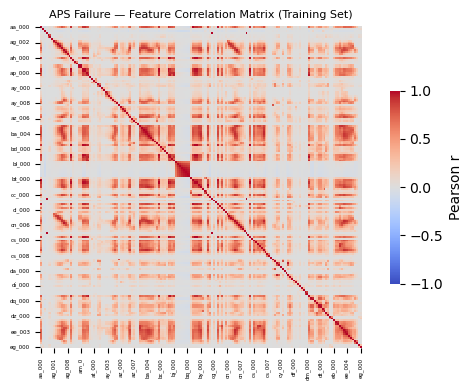

In [16]:
scaler = StandardScaler()
X_train_std = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
assert 'X_train' in globals()
print("X_train shape:", X_train.shape)
print("Total missing values in X_train:", X_train.isna().sum().sum())   

X_train_corr = X_train_std.loc[:, X_train_std.nunique() > 1].copy()
print("Features before dropping constant columns:", X_train.shape[1], "After:", X_train_corr.shape[1])

corr = X_train_corr.corr(method="pearson")
print("Correlation matrix shape:", corr.shape)     

plt.figure(figsize=(6, 4))
sns.heatmap(
    corr,
    cmap="coolwarm",
    vmin=-1, vmax=1,
    center=0,
    square=True,
    annot=False,
    linewidths=0,
    cbar_kws={"shrink": 0.6, "label": "Pearson r"}
)
plt.title("APS Failure — Feature Correlation Matrix (Training Set)", fontsize=8)
plt.xticks(fontsize=4, rotation=90)
plt.yticks(fontsize=4, rotation=0)
plt.tight_layout()
plt.savefig("aps_corr_matrix_full.png", dpi=200, bbox_inches="tight")
plt.show()

#### (iv) Make scatter plots and box plots

Number of selected features: 13
Selected features: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


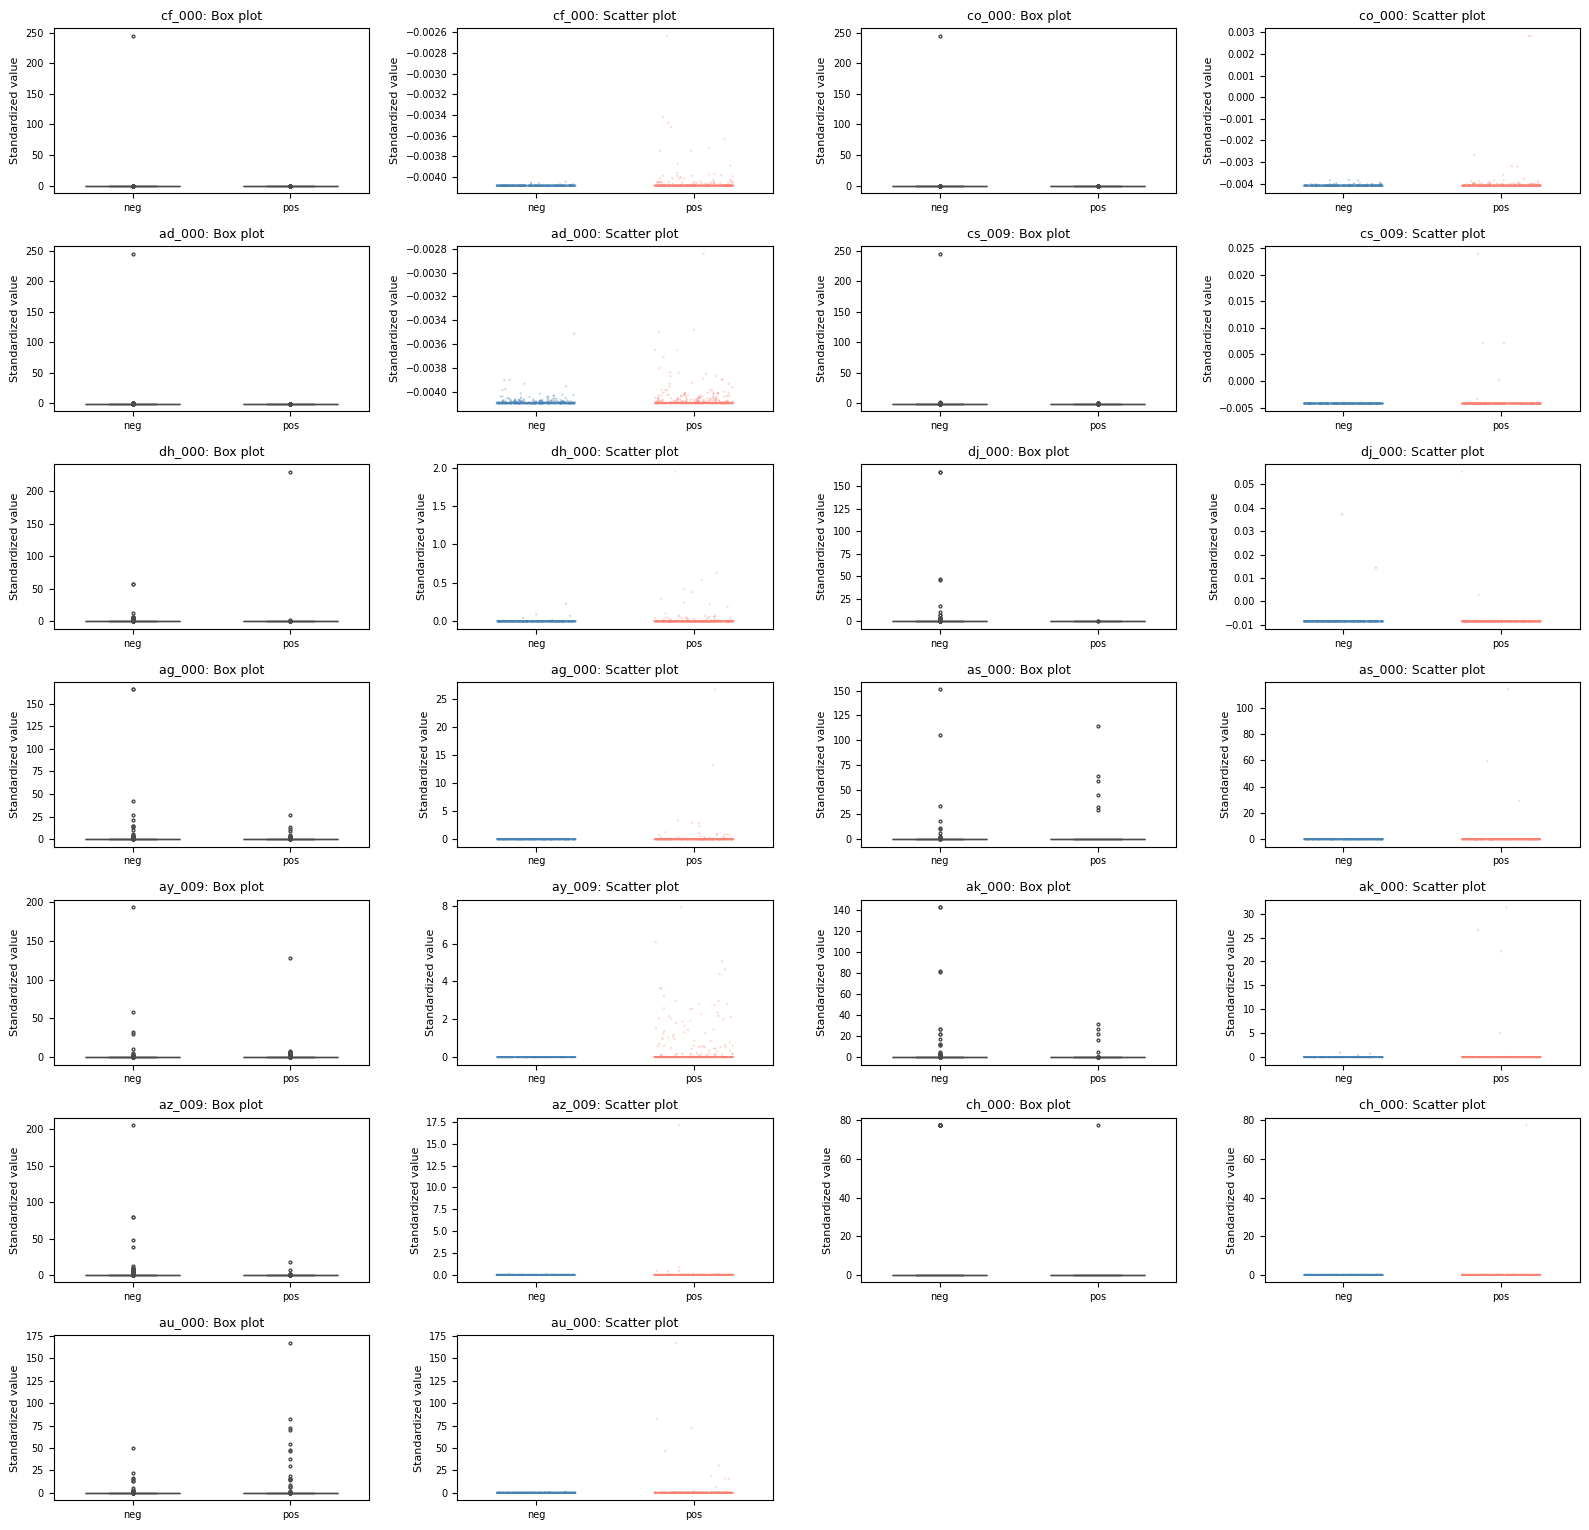

In [18]:
scaler = StandardScaler()
X_train_std = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

n_features = int(np.sqrt(X_train.shape[1]))
top_features = cv.dropna().nlargest(n_features).index.tolist()

print("Number of selected features:", len(top_features))
print("Selected features:", top_features)

df_vis = X_train_std[top_features].copy()
df_vis["class"] = y_train.map({0: "neg", 1: "pos"})

df_plot = pd.concat([
    group.sample(n=min(len(group), 600), random_state=42)
    for _, group in df_vis.groupby("class")
], ignore_index=True)

palette = {"neg": "steelblue", "pos": "salmon"}
class_order = ["neg", "pos"]

nrows = int(np.ceil(n_features / 2))
fig, axes = plt.subplots(
    nrows, 4,
    figsize=(16, 2.2 * nrows)
)

for idx, feature in enumerate(top_features):
    row = idx // 2
    col = (idx % 2) * 2
    ax_box = axes[row, col]

    sns.boxplot(
        data=df_vis,
        x="class",
        y=feature,
        hue="class",
        order=class_order,
        hue_order=class_order,
        palette=palette,
        legend=False,
        width=0.6,
        fliersize=2,
        ax=ax_box
    )

    ax_box.set_title(f"{feature}: Box plot", fontsize=9)
    ax_box.set_xlabel("")
    ax_box.set_ylabel("Standardized value", fontsize=8)
    ax_box.tick_params(labelsize=7)
    ax_scatter = axes[row, col + 1]

    sns.stripplot(
        data=df_plot,
        x="class",
        y=feature,
        hue="class",
        order=class_order,
        hue_order=class_order,
        palette=palette,
        legend=False,
        jitter=0.25,
        size=1.5,
        alpha=0.35,
        ax=ax_scatter
    )

    ax_scatter.set_title(
        f"{feature}: Scatter plot", fontsize=9
    )
    ax_scatter.set_xlabel("")
    ax_scatter.set_ylabel("Standardized value", fontsize=8)
    ax_scatter.tick_params(labelsize=7)

for idx in range(n_features, nrows * 2):
    row = idx // 2
    col = (idx % 2) * 2
    axes[row, col].axis("off")
    axes[row, col + 1].axis("off")

plt.tight_layout()
plt.show()

No. Most features show severe overlap between the positive and negative classes. A high CV only reflects relative dispersion (many zeros mixed with large values) and does not imply strong discriminative power. Although a few features show a slight upward shift for the positive class, visual inspection of scatter plots alone cannot establish strict statistical significance.

#### (v) Is this data set imbalanced?

In [21]:
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
total = len(y_train)
print(f"Number of negative (neg) data: {neg_count}")
print(f"Number of positive (pos) data: {pos_count}")
print(f"Total training data: {total}")
print(f"Positive class percentage: {pos_count / total:.2%}")
print("Is this data set imbalanced?")
if pos_count / total < 0.2:  
    print("Yes, the dataset is highly imbalanced.")
else:
    print("No, the dataset is roughly balanced.")

Number of negative (neg) data: 59000
Number of positive (pos) data: 1000
Total training data: 60000
Positive class percentage: 1.67%
Is this data set imbalanced?
Yes, the dataset is highly imbalanced.


### (c) Train a random forest


Training Set
Confusion Matrix:
[[59000     0]
 [    1   999]]
Misclassified observations: 1
Misclassification Rate: 0.000017 (0.0017%)
AUC: 1.0000
Total Cost (10*FP + 500*FN): 500

Test Set
Confusion Matrix:
[[15610    15]
 [  106   269]]
Misclassified observations: 121
Misclassification Rate: 0.007563 (0.7563%)
AUC: 0.9928
Total Cost (10*FP + 500*FN): 53150


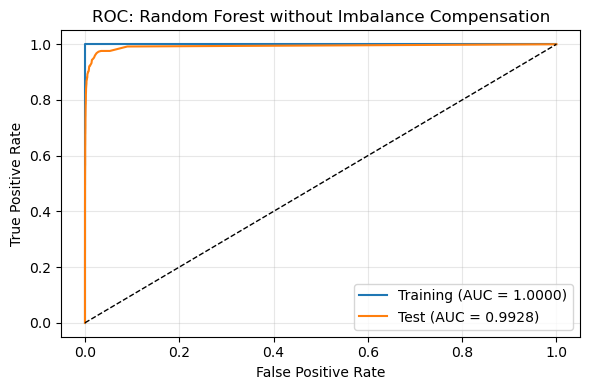


OOB vs. Test Error
OOB Error:  0.006117 (0.6117%)
Test Error: 0.007563 (0.7563%)
Absolute Difference: 0.001446


In [23]:
def evaluate_model(model, X, y_true, dataset_name):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    error = 1 - accuracy_score(y_true, y_pred)
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    roc_auc = auc(fpr, tpr)
    total_cost = 10 * fp + 500 * fn
    print(f"\n{dataset_name} Set")
    print("Confusion Matrix:")
    print(cm)
    print(f"Misclassified observations: {fp + fn}")
    print(f"Misclassification Rate: {error:.6f} ({error:.4%})")
    print(f"AUC: {roc_auc:.4f}")
    print(f"Total Cost (10*FP + 500*FN): {total_cost}")
    return fpr, tpr, roc_auc  
rf = RandomForestClassifier(
    n_estimators=100,
    class_weight=None,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)
fpr_train, tpr_train, auc_train = evaluate_model(
    rf, X_train, y_train, "Training"
)

fpr_test, tpr_test, auc_test = evaluate_model(
    rf, X_test, y_test, "Test"
)
plt.figure(figsize=(6, 4))

plt.plot(
    fpr_train, tpr_train,
    label=f"Training (AUC = {auc_train:.4f})"
)
plt.plot(
    fpr_test, tpr_test,
    label=f"Test (AUC = {auc_test:.4f})"
)
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC: Random Forest without Imbalance Compensation")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
oob_error = 1 - rf.oob_score_
test_error = 1 - accuracy_score(y_test, rf.predict(X_test))
print("\nOOB vs. Test Error")
print(f"OOB Error:  {oob_error:.6f} ({oob_error:.4%})")
print(f"Test Error: {test_error:.6f} ({test_error:.4%})")
print(f"Absolute Difference: {abs(oob_error - test_error):.6f}")

Misclassification: Training error is 0.0017%, and test error is 0.7563% (TN = 15,610, FP = 15, FN = 106, TP = 269). Despite the low overall error, the model misses 28.27% of positive test cases.
ROC & AUC: Training AUC ≈ 1.0000 and test AUC = 0.9928, indicating strong discrimination.
Total Cost: Test cost is 53150 (10 × 15 + 500 × 106), mainly caused by false negatives.
OOB vs. Test Error: OOB error (0.6117%) is close to test error (0.7563%), supporting its usefulness as an error estimate. However, this alone does not rule out overfitting.

### (d) Research class imbalance in random forest


Training (Weighted RF) Set
Confusion Matrix:
[[59000     0]
 [    1   999]]
Misclassified observations: 1
Misclassification Rate: 0.000017 (0.0017%)
AUC: 1.0000
Total Cost (10*FP + 500*FN): 500

Test (Weighted RF) Set
Confusion Matrix:
[[15609    16]
 [  156   219]]
Misclassified observations: 172
Misclassification Rate: 0.010750 (1.0750%)
AUC: 0.9904
Total Cost (10*FP + 500*FN): 78160


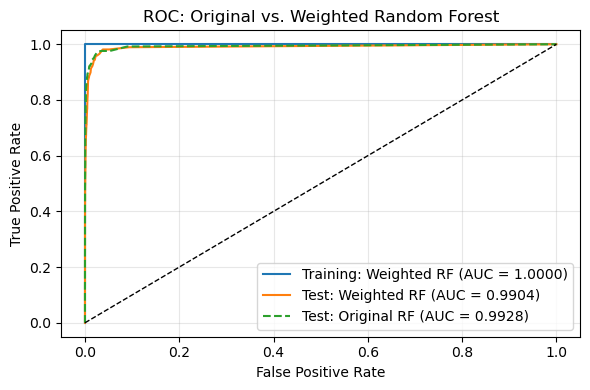


Original vs. Weighted Random Forest
      Model  Test Error (%)  Test AUC  OOB Error (%)
Original RF          0.7563    0.9928         0.6117
Weighted RF          1.0750    0.9904         0.7883


In [26]:
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    oob_score=True,
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train, y_train)
fpr_train_b, tpr_train_b, auc_train_b = evaluate_model(
    rf_balanced, X_train, y_train, "Training (Weighted RF)"
)
fpr_test_b, tpr_test_b, auc_test_b = evaluate_model(
    rf_balanced, X_test, y_test, "Test (Weighted RF)"
)
plt.figure(figsize=(6, 4))
plt.plot(
    fpr_train_b, tpr_train_b,
    label=f"Training: Weighted RF (AUC = {auc_train_b:.4f})"
)
plt.plot(
    fpr_test_b, tpr_test_b,
    label=f"Test: Weighted RF (AUC = {auc_test_b:.4f})"
)
plt.plot(
    fpr_test, tpr_test,
    linestyle="--",
    label=f"Test: Original RF (AUC = {auc_test:.4f})"
)
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC: Original vs. Weighted Random Forest")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
test_error_b = 1 - accuracy_score(
    y_test, rf_balanced.predict(X_test)
)
oob_error_b = 1 - rf_balanced.oob_score_
comparison = pd.DataFrame({
    "Model": ["Original RF", "Weighted RF"],
    "Test Error (%)": [
        100 * (1 - accuracy_score(y_test, rf.predict(X_test))),
        100 * test_error_b
    ],
    "Test AUC": [auc_test, auc_test_b],
    "OOB Error (%)": [
        100 * (1 - rf.oob_score_),
        100 * oob_error_b
    ]
})
print("\nOriginal vs. Weighted Random Forest")
print(comparison.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

Class imbalance in random forests can be addressed through class weighting, minority-class oversampling, or majority-class undersampling. In this experiment, I used `class_weight="balanced_subsample"`, which calculates class weights inversely proportional to class frequencies within each tree’s bootstrap sample, giving minority-class observations greater weight during training.
The weighted random forest has a training error of 0.0017%, a test error of 1.0750%, and a test AUC of 0.9904. Its OOB error of 0.7883% underestimates the observed test error.
Compared with the original random forest, test error increased from 0.7563% to 1.0750%, while test AUC decreased from 0.9928 to 0.9904. False negatives increased from 106 to 156, raising the total cost from 53150 to 78160. Therefore, class weighting did not improve performance under this configuration.

### (e) XGBoost and Model Trees

Tuning alpha via 5-fold CV
Best alpha found: 1

Training Set
Confusion Matrix:
[[59000     0]
 [   37   963]]
Misclassified observations: 37
Misclassification Rate: 0.000617 (0.0617%)
AUC: 0.9999
Total Cost (10*FP + 500*FN): 18500

Test Set
Confusion Matrix:
[[15606    19]
 [   91   284]]
Misclassified observations: 110
Misclassification Rate: 0.006875 (0.6875%)
AUC: 0.9958
Total Cost (10*FP + 500*FN): 45690

CV Error vs. Test Error
5-Fold CV Misclassification Error: 0.005917 (0.5917%)
Test Misclassification Error:      0.006875 (0.6875%)


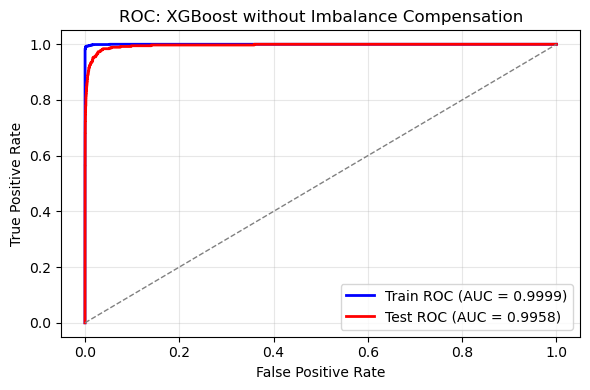

In [29]:
X_train_raw = train.drop(columns="class")
xgb_base = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    objective="binary:logistic",
    eval_metric="logloss",
    n_jobs=1
)
xgb_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", xgb_base)
])
param_grid = {
    "xgb__reg_alpha": [0, 0.1, 1, 10, 100]
}
grid_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="neg_log_loss",
    n_jobs=-1
)

print("Tuning alpha via 5-fold CV")
grid_search.fit(X_train_raw, y_train)
best_alpha = grid_search.best_params_["xgb__reg_alpha"]
best_xgb = grid_search.best_estimator_

print(f"Best alpha found: {best_alpha}")
def evaluate_xgb_model(model, X, y_true, dataset_name):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    misclass_rate = 1 - accuracy_score(y_true, y_pred)
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    roc_auc = auc(fpr, tpr)
    total_cost = 10 * fp + 500 * fn

    print(f"\n{dataset_name} Set")
    print("Confusion Matrix:")
    print(cm)
    print(f"Misclassified observations: {fp + fn}")
    print(
        f"Misclassification Rate: {misclass_rate:.6f} "
        f"({misclass_rate:.4%})"
    )
    print(f"AUC: {roc_auc:.4f}")
    print(f"Total Cost (10*FP + 500*FN): {total_cost}")

    return fpr, tpr, roc_auc, misclass_rate
fpr_train, tpr_train, auc_train, err_train = evaluate_xgb_model(
    best_xgb, X_train_raw, y_train, "Training"
)
fpr_test, tpr_test, auc_test, err_test = evaluate_xgb_model(
    best_xgb, X_test, y_test, "Test"
)
cv_acc_scores = cross_val_score(
    best_xgb,
    X_train_raw,
    y_train,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

cv_error = 1 - cv_acc_scores.mean()
print("\nCV Error vs. Test Error")
print(
    f"5-Fold CV Misclassification Error: "
    f"{cv_error:.6f} ({cv_error:.4%})"
)
print(
    f"Test Misclassification Error:      "
    f"{err_test:.6f} ({err_test:.4%})"
)

plt.figure(figsize=(6, 4))

plt.plot(
    fpr_train, tpr_train,
    color="blue",
    lw=2,
    label=f"Train ROC (AUC = {auc_train:.4f})"
)
plt.plot(
    fpr_test, tpr_test,
    color="red",
    lw=2,
    label=f"Test ROC (AUC = {auc_test:.4f})"
)
plt.plot(
    [0, 1], [0, 1],
    color="gray",
    lw=1,
    linestyle="--"
)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC: XGBoost without Imbalance Compensation")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The selected regularization parameter is α = 1. The 5-fold CV error (0.5917%) is close to the test error (0.6875%), suggesting reasonably consistent predictive performance. Training and test AUCs are 0.9999 and 0.9958, indicating strong discrimination.
However, the model misses 91 of the 375 positive test observations (24.27%), resulting in a total cost of 45690 (10 × 19 + 500 × 91).

### (f) Use SMOTE to pre-process your data

Tuning alpha with SMOTE via 5-fold CV
Fitting 5 folds for each of 5 candidates, totalling 25 fits

Best alpha found (SMOTE): 0.1

Training (SMOTE XGBoost) Set
Confusion Matrix:
[[58824   176]
 [   33   967]]
Misclassified observations: 209
Misclassification Rate: 0.003483 (0.3483%)
AUC: 0.9994
Total Cost (10*FP + 500*FN): 18260

Test (SMOTE XGBoost) Set
Confusion Matrix:
[[15497   128]
 [   49   326]]
Misclassified observations: 177
Misclassification Rate: 0.011062 (1.1062%)
AUC: 0.9940
Total Cost (10*FP + 500*FN): 25780
CV Error vs. Test Error
5-Fold CV Misclassification Error: 0.009617 (0.9617%)
Test Misclassification Error:      0.011062 (1.1062%)


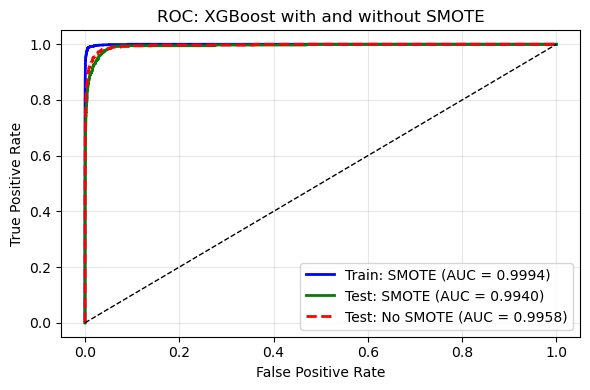

XGBoost: Without SMOTE vs. With SMOTE
          Model  Test Error (%)  Test AUC  False Negatives  Total Cost
        XGBoost          0.6875    0.9958               91       45690
SMOTE + XGBoost          1.1062    0.9940               49       25780


In [32]:
xgb_smote_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("smote", SMOTE(random_state=42)),
    ("xgb", clone(xgb_base))
])
grid_search_smote = GridSearchCV(
    estimator=xgb_smote_pipeline,
    param_grid={
        "xgb__reg_alpha": [0, 0.1, 1, 10, 100]
    },
    scoring={
        "neg_log_loss": "neg_log_loss",
        "accuracy": "accuracy"
    },
    refit="neg_log_loss",
    cv=5,
    n_jobs=-1,
    pre_dispatch="n_jobs",
    verbose=1
)
print("Tuning alpha with SMOTE via 5-fold CV")
grid_search_smote.fit(X_train_raw, y_train)
best_pipeline = grid_search_smote.best_estimator_
best_alpha_smote = grid_search_smote.best_params_["xgb__reg_alpha"]
best_index_smote = grid_search_smote.best_index_
cv_error_smote = 1 - grid_search_smote.cv_results_[
    "mean_test_accuracy"
][best_index_smote]
print(f"\nBest alpha found (SMOTE): {best_alpha_smote}")
fpr_train_s, tpr_train_s, auc_train_s, err_train_s = (
    evaluate_xgb_model(
        best_pipeline,
        X_train_raw,
        y_train,
        "Training (SMOTE XGBoost)"
    )
)
fpr_test_s, tpr_test_s, auc_test_s, err_test_s = (
    evaluate_xgb_model(
        best_pipeline,
        X_test,
        y_test,
        "Test (SMOTE XGBoost)"
    )
)
print("CV Error vs. Test Error")
print(
    f"5-Fold CV Misclassification Error: "
    f"{cv_error_smote:.6f} ({cv_error_smote:.4%})"
)
print(
    f"Test Misclassification Error:      "
    f"{err_test_s:.6f} ({err_test_s:.4%})"
)
plt.figure(figsize=(6, 4))
plt.plot(
    fpr_train_s, tpr_train_s,
    color="blue",
    lw=2,
    label=f"Train: SMOTE (AUC = {auc_train_s:.4f})"
)
plt.plot(
    fpr_test_s, tpr_test_s,
    color="green",
    lw=2,
    label=f"Test: SMOTE (AUC = {auc_test_s:.4f})"
)
plt.plot(
    fpr_test, tpr_test,
    color="red",
    lw=2,
    linestyle="--",
    label=f"Test: No SMOTE (AUC = {auc_test:.4f})"
)
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC: XGBoost with and without SMOTE")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
cm_original = confusion_matrix(
    y_test, best_xgb.predict(X_test), labels=[0, 1]
)
cm_smote = confusion_matrix(
    y_test, best_pipeline.predict(X_test), labels=[0, 1]
)
comparison = pd.DataFrame({
    "Model": ["XGBoost", "SMOTE + XGBoost"],
    "Test Error (%)": [100 * err_test, 100 * err_test_s],
    "Test AUC": [auc_test, auc_test_s],
    "False Negatives": [
        cm_original[1, 0],
        cm_smote[1, 0]
    ],
    "Total Cost": [
        10 * cm_original[0, 1] + 500 * cm_original[1, 0],
        10 * cm_smote[0, 1] + 500 * cm_smote[1, 0]
    ]
})
print("XGBoost: Without SMOTE vs. With SMOTE")
print(comparison.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

Compared with the original XGBoost model, SMOTE increased the test misclassification rate from 0.6875% to 1.1062%. However, false negatives decreased from 91 to 49, and positive-class recall increased from 75.73% to 86.93%. Although false positives increased from 19 to 128, the total cost decreased from 45690 to 25780 because false negatives carry a much higher cost. Therefore, SMOTE improved positive-class detection and reduced the total cost despite increasing the overall misclassification rate.

## 2. ISLR 6.6.3

**A**.**iv**As s increases, the constraint on the coefficients is relaxed, meaning the model becomes more flexible and can fit the training data better. Since training RSS is the objective function being minimized, a larger feasible region can only lead to an equal or smaller minimum value.Thus,training RSS steadily decreases.
**B**.**ii**At very low s,the model is highly restricted (high bias), resulting in high test RSS. As increases, bias decreases faster than variance increases, reducing test error. If s gets too large, the model overfits the training data (high variance), causing the test RSS to eventually increase, forming a U-shape.
**C**.**iii** When $s=0$, the model is highly constrained (slopes are forced to zero), resulting in the lowest possible variance. As $s$ increases, the constraint is relaxed, and the model becomes more flexible and fits the specific training data more closely (including its noise). Consequently, its variance steadily increases.
**D**.**iv**At s=0, the model is overly simplistic, resulting in maximum bias. As the model becomes more flexible (s increases), it can better approximate the true relationship, leading to a steady decrease in bias.
**E**. **V**The irreducible error is the inherent noise in the data. It is a property of the data-generating process. No matter what statistical model or regularization parameter s we use, the irreducible error remains constant.

## 3. ISLR 6.6.5

**A**.The ridge regression optimization problem is to minimize the RSS plus an L2 penalty:
$$
y=y_1=-y_2,\qquad
x=x_{11}=x_{12}=-x_{21}=-x_{22}
$$
$$
\min_{\beta_1,\beta_2}
\left[
2\left(y-x(\beta_1+\beta_2)\right)^2
+\lambda(\beta_1^2+\beta_2^2)
\right]
$$
**B**.The objective function is perfectly symmetric with respect to $\beta_1$ and $\beta_2$. Taking the partial derivatives with respect to $\beta_1$ and $\beta_2$ and setting them to zero yields two equations. Subtracting one from the other gives

$$
2\lambda(\beta_1-\beta_2)=0.
$$

Since $\lambda>0$, it must be that

$$
\beta_1=\beta_2.
$$
**C**.The lasso optimization problem minimizes the RSS plus an L1 penalty:

$$
\min_{\beta_1,\beta_2}
\left[
2\left(y-x(\beta_1+\beta_2)\right)^2
+\lambda\left(|\beta_1|+|\beta_2|\right)
\right]
$$
**D**.The RSS depends only on the sum $S=\beta_1+\beta_2$. The penalty is $|\beta_1|+|\beta_2|$. By the triangle inequality,

$$
|\beta_1|+|\beta_2|\geq|\beta_1+\beta_2|.
$$

Equality holds if and only if $\beta_1$ and $\beta_2$ have the same sign (both $\geq 0$ or both $\leq 0$).

Thus, for a fixed optimal sum $S^*$, any allocation between $\beta_1$ and $\beta_2$ (as long as they don't have opposite signs) yields the exact same objective value.

## 4. ISLR 8.4.5

**Majority Vote**:We classify each estimate using a threshold of 0.5. Estimates $>0.5$ vote for "Red", and estimates $\leq 0.5$ vote for "Green".
Out of the 10 estimates, there are 6 values $>0.5$ (0.55, 0.6, 0.6, 0.65, 0.7, 0.75) and 4 values $\leq 0.5$ (0.1, 0.15, 0.2, 0.2).
Final classification: Red

**Average Probability**:We calculate the average of the 10 probability estimates:
$$
\begin{aligned}
\text{Average}
&= \frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}&= 0.45
\end{aligned}
$$

Since the average probability $0.45<0.5$, the model predicts the class with the highest probability.

Final classification: Green.

## 5. ISLR 9.7.3

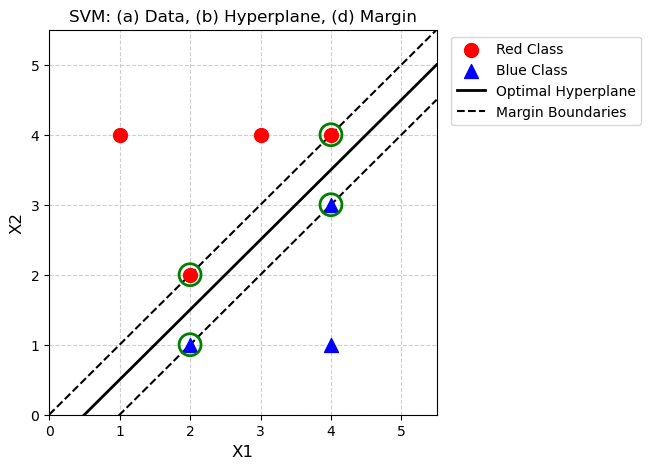

In [41]:
plt.figure(figsize=(5, 5))
red_points = [(1, 4), (2, 2), (3, 4), (4, 4)] #(a)
blue_points = [(2, 1), (4, 1), (4, 3)]
rx, ry = zip(*red_points)
bx, by = zip(*blue_points)
plt.scatter(rx, ry, color='red', s=100, marker='o', label='Red Class', zorder=3)
plt.scatter(bx, by, color='blue', s=100, marker='^', label='Blue Class', zorder=3)
x_vals = np.linspace(0, 5.5, 100)
plt.plot(x_vals, x_vals - 0.5, 'k-', linewidth=2, label='Optimal Hyperplane', zorder=2) #(b)
plt.plot(x_vals, x_vals, 'k--', linewidth=1.5, label='Margin Boundaries', zorder=2) #(d)
plt.plot(x_vals, x_vals - 1, 'k--', linewidth=1.5, zorder=2)
support_vectors = [(2, 2), (4, 4), (2, 1), (4, 3)]# (e)
for sv in support_vectors:
    plt.scatter(sv[0], sv[1], s=250, facecolors='none', edgecolors='green', linewidth=2, zorder=4)
plt.xlim(0, 5.5)
plt.ylim(0, 5.5)
plt.xlabel('X1', fontsize=12)
plt.ylabel('X2', fontsize=12)
plt.title('SVM: (a) Data, (b) Hyperplane, (d) Margin', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.show()

**A**. Please refer to the sketch above.

**B**.Draw a straight line through the red point (2, 2):
$$
X_2=X_1
$$
Draw a straight line through the blue point (2, 1):
$$
X_2=X_1-1
$$
The red line has a value of $0$, while the blue line has a value of $-1$.
The midpoint value is:$$
\frac{0+(-1)}{2}=-0.5
$$
Therefore, the equation of the middle line is:
$$
\boxed{X_2=X_1-0.5}
$$
**C**.
Choose:

$$
\boxed{\beta_0=\frac12,\qquad \beta_1=-1,\qquad \beta_2=1}
$$

Therefore:

$$
\widehat Y=
\begin{cases}
\text{Red}, & \frac12-X_1+X_2>0,\\
\text{Blue}, & \frac12-X_1+X_2\leq0.
\end{cases}
$$
**D**.Please refer to the sketch above.

**E**.The support vectors are the points lying exactly on the margin boundaries: Red points (2,2), (4,4), and Blue points (2,1), (4,3).

**F**.The 7th point (4,1) is far from the margin and is not a support vector. The hyperplane is determined solely by support vectors, so moving it slightly does not affect it.

**G**.A hyperplane shifted towards the Red class. It separates the classes but does not maximize the margin.

Equation:

$$
\boxed{X_2=X_1-0.2}
$$
**H**.Add a new **blue point**:
$$
\boxed{(X_1,X_2)=(3,3),\qquad Y=\text{Blue}}
$$

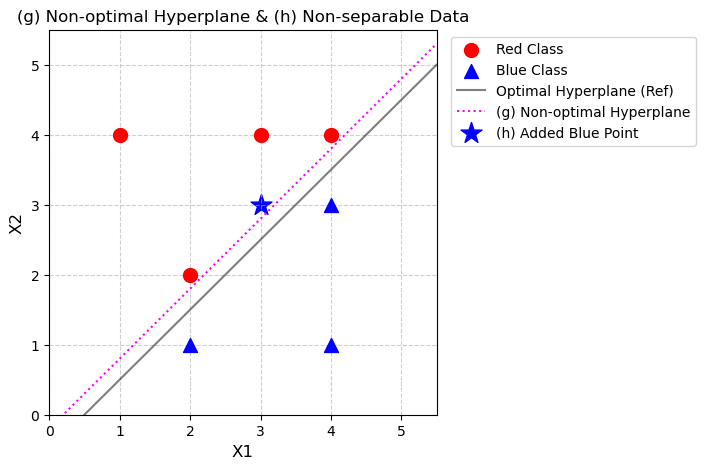

In [43]:
plt.figure(figsize=(5, 5))
red_points = [(1, 4), (2, 2), (3, 4), (4, 4)]
blue_points = [(2, 1), (4, 1), (4, 3)]
rx, ry = zip(*red_points)
bx, by = zip(*blue_points)
plt.scatter(rx, ry, color='red', s=100, marker='o', label='Red Class', zorder=3)
plt.scatter(bx, by, color='blue', s=100, marker='^', label='Blue Class', zorder=3)
x_vals = np.linspace(0, 5.5, 100)
plt.plot(x_vals, x_vals - 0.5, 'k-', linewidth=1.5, alpha=0.5, label='Optimal Hyperplane (Ref)')
plt.plot(x_vals, x_vals - 0.2, color='magenta', linestyle=':', label='(g) Non-optimal Hyperplane') #(g)
plt.scatter(3, 3, color='blue', s=250, marker='*',label='(h) Added Blue Point') #(h)
plt.xlim(0, 5.5)
plt.ylim(0, 5.5)
plt.xlabel('X1', fontsize=12)
plt.ylabel('X2', fontsize=12)
plt.title('(g) Non-optimal Hyperplane & (h) Non-separable Data', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper left', bbox_to_anchor=(1.02, 1))
plt.show()